<a href="https://colab.research.google.com/github/BhoomiMahna/CognitiveUCS420/blob/main/assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170282       # <-- your full roll number
NAME = "Bhoomi Mahna"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170282   Name: Bhoomi Mahna   Fingerprint: 545EC317   Tickets: 14

Ticket_ID                                                                    Ticket_Text
      T01                      The printer is not working. It works on another computer.
      T02                    I reinstalled the VPN since yesterday. It worked yesterday.
      T03     Server is showing an error when connected to campus Wi-Fi. This is urgent.
      T04                          The Python keeps asking for login. Please resolve it.
      T05                                    I can't login and I didn't change anything.
      T06                                             Dr. Rao's lab PC (No. 14) is down.
      T07                                The wifi crashes while opening. This is urgent.
      T08         Printer crashes while opening on my laptop. I don't know what changed.
      T09       I was locked out of the e-mail after restarting the system. Please help.
      T10                 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Your code
ans=[]
for _,rows in df.iterrows():
  a=process_ticket(rows['Ticket_Text'])
  ans.append(a)
table=pd.DataFrame(ans)
print(table.to_string(index=False))

                                                                        sentences                                                                                             tokens        punct                                           stops                                                      final
                     [The printer is not working., It works on another computer.]                           [the, printer, is, not, working, ., it, works, on, another, computer, .]       [., .]                          [the, is, not, it, on]               [printer, working, works, another, computer]
                   [I reinstalled the VPN since yesterday., It worked yesterday.]                          [i, reinstalled, the, vpn, since, yesterday, ., it, worked, yesterday, .]       [., .]                                    [i, the, it]    [reinstalled, vpn, since, yesterday, worked, yesterday]
    [Server is showing an error when connected to campus Wi-Fi., This is urgent.]       [server, 

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* As we performed unigram tokenisation, so we get these unrealw ords like n't 's etc


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re
for text in df['Ticket_Text']:
  longword=re.findall(r'\b[A-Za-z]{6,}\b',text)
  numbers=re.findall(r'\b\d+(?:\.\d+)*\b',text)
  capital=re.findall(r'\b[A-Z][a-zA-Z]*\b',text)
  vowel=re.findall(r'\b[aeiouAEIOU][a-zA-Z]*\b',text)

  print("Long words:", longword)
  print("Numbers:", numbers)
  print("Capitalized words:", capital)
  print("Words starting with vowel:", vowel)
  print("-" * 50)

Long words: ['printer', 'working', 'another', 'computer']
Numbers: []
Capitalized words: ['The', 'It']
Words starting with vowel: ['is', 'It', 'on', 'another']
--------------------------------------------------
Long words: ['reinstalled', 'yesterday', 'worked', 'yesterday']
Numbers: []
Capitalized words: ['I', 'VPN', 'It']
Words starting with vowel: ['I', 'It']
--------------------------------------------------
Long words: ['Server', 'showing', 'connected', 'campus', 'urgent']
Numbers: []
Capitalized words: ['Server', 'Wi', 'Fi', 'This']
Words starting with vowel: ['is', 'an', 'error', 'is', 'urgent']
--------------------------------------------------
Long words: ['Python', 'asking', 'Please', 'resolve']
Numbers: []
Capitalized words: ['The', 'Python', 'Please']
Words starting with vowel: ['asking', 'it']
--------------------------------------------------
Long words: ['change', 'anything']
Numbers: []
Capitalized words: ['I', 'I']
Words starting with vowel: ['I', 'and', 'I', 'anything'

In [7]:
def clean_text(text):
    text = re.sub(r'https?://\S+|www\.\S+', '<URL>', text)
    text = re.sub(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b','<EMAIL>',text)
    text = re.sub(r'(?<!\w)(?:\+91[\s-]*)?(?:\d[\s-]*){10}(?!\w)','<PHONE>',text)

    return text

for line in TEST_LINES:
    print(clean_text(line))

Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, <PHONE> or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Most capitalized words are only because they begin a sentence, such as The, Please, Call, and Password. words like Python, Matlab, and VPN are proper names or acronyms. 15 capitalized words are capitalize

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
# Your code
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""https?://[^\s]+|www\.[^\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d+(?:[\s-]+\d+)+|\d+(?:\.\d+)+|\w+(?:[-']\w+)*"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

import pandas as pd
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""https?://[^\s<>"']*[A-Za-z0-9/#?=&_%~-]|www\.[^\s<>"']*[A-Za-z0-9/#?=&_%~-]|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d+(?:[\s-]+\d+)+|\d+(?:\.\d+)+|\w+(?:[-']\w+)*"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)


for line in TEST_LINES:
    print("Original:", line)
    print("Custom:  ", my_tokenize(line))
    print("NLTK:    ", word_tokenize(line))
    print("-" * 80)

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    print("\nTicket:", row["Ticket_ID"])
    print("Custom: ", my_tokenize(text))
    print("NLTK: ", word_tokenize(text))

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it']
NLTK:     ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
--------------------------------------------------------------------------------
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom:   ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
NLTK:     ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
------------------------------------------------

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*  all tickets are tokenised differently, as my_tokenize keeps can't and don't as single token but word_tokenize splits them into ca and n't


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [11]:
import string
from nltk.tokenize import word_tokenize
S3 = []
for text in df["Ticket_Text"]:
    S3.extend(my_tokenize(text))

print("S3:", S3)


S3: ['The', 'printer', 'is', 'not', 'working', 'It', 'works', 'on', 'another', 'computer', 'I', 'reinstalled', 'the', 'VPN', 'since', 'yesterday', 'It', 'worked', 'yesterday', 'Server', 'is', 'showing', 'an', 'error', 'when', 'connected', 'to', 'campus', 'Wi-Fi', 'This', 'is', 'urgent', 'The', 'Python', 'keeps', 'asking', 'for', 'login', 'Please', 'resolve', 'it', 'I', "can't", 'login', 'and', 'I', "didn't", 'change', 'anything', 'Dr', "Rao's", 'lab', 'PC', 'No', '14', 'is', 'down', 'The', 'wifi', 'crashes', 'while', 'opening', 'This', 'is', 'urgent', 'Printer', 'crashes', 'while', 'opening', 'on', 'my', 'laptop', 'I', "don't", 'know', 'what', 'changed', 'I', 'was', 'locked', 'out', 'of', 'the', 'e-mail', 'after', 'restarting', 'the', 'system', 'Please', 'help', 'Ticket', '4521', 'is', 'still', 'open', 'I', 'cannot', 'access', 'the', 'Matlab', 'before', 'the', 'assignment', 'deadline', 'Can', 'you', 'check', 'this', 'Password', 'is', 'showing', 'an', 'error', 'while', 'uploading', 'the

In [16]:
# Your code
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')

words=sorted(set(
    w.lower() for w in S3
    if re.fullmatch(r"[a-zA-Z]+",w)
))

porter=PorterStemmer()
lancaster=LancasterStemmer()
regexx=RegexpStemmer(r'(ing|edly|ed|ly|es|s)$',min=4)
lemmatizer=WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'
    if tag.startswith('V'):
        return 'v'
    if tag.startswith('N'):
        return 'n'
    if tag.startswith('R'):
        return 'r'
    return 'n'

tagged_words = pos_tag(words)

results = []

for word, tag in tagged_words:
    pos = get_wordnet_pos(tag)

    results.append({
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regex": regexx.stem(word),
        "Lemma": lemmatizer.lemmatize(word, pos=pos)
    })

stem_df = pd.DataFrame(results)

columns = ["Porter", "Lancaster", "Regex", "Lemma"]
different = stem_df[stem_df[columns].nunique(axis=1) > 1]

print(different.to_string(index=False))

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


       Word   Porter Lancaster      Regex      Lemma
     access   access    access      acces     access
      after    after       aft      after      after
    another    anoth     anoth    another    another
   anything    anyth     anyth      anyth   anything
 assignment   assign    assign assignment assignment
     before    befor       bef     before     before
     campus    campu      camp      campu     campus
     change    chang     chang     change     change
    changed    chang     chang      chang     change
   computer   comput    comput   computer   computer
   deadline  deadlin   deadlin   deadline   deadline
      error    error        er      error      error
       file     file       fil       file       file
         is       is        is         is         be
        lms       lm       lms        lms         lm
       open     open        op       open       open
    opening     open        op       open       open
     please    pleas     pleas     please     

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

overstemming - campus->camp , printer->print
understemming - change, changed->change, chang

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Corpus statistics:
Corpus  Total Tokens  Unique Tokens    TTR
    S1           166             99 0.5964
    S2           137             93 0.6788
    S3           132             91 0.6894
    S4           132             83 0.6288

Top 10 words in S1:
[('.', 23), ('the', 10), ('is', 7), ('i', 6), ('this', 4), ('it', 3), ('please', 3), ("n't", 3), ('crashes', 3), ('while', 3)]

Top 10 words in S3:
[('the', 10), ('is', 7), ('i', 6), ('this', 4), ('it', 3), ('please', 3), ('crashes', 3), ('while', 3), ('printer', 2), ('on', 2)]


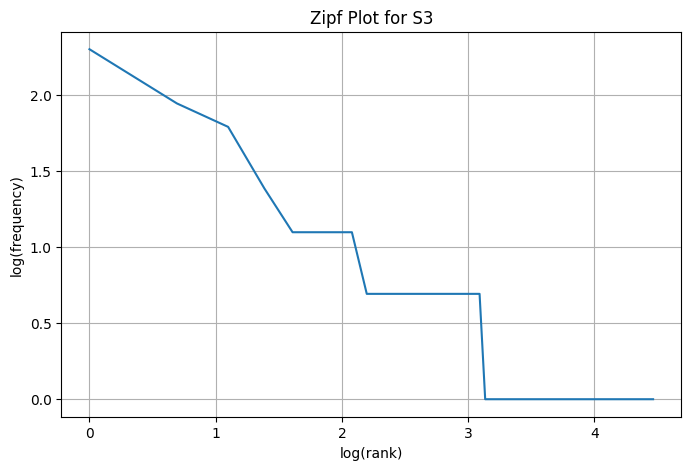


Top 5 bigrams in S1:
[(('.', 'i'), 5), (('.', 'the'), 3), (('.', 'please'), 3), (('.', 'it'), 2), (('yesterday', '.'), 2)]

Top 5 bigrams in S3:
[(('is', 'showing'), 2), (('showing', 'an'), 2), (('an', 'error'), 2), (('this', 'is'), 2), (('is', 'urgent'), 2)]


In [21]:
# Your code

from collections import Counter
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from nltk.util import bigrams
import math

S1 = []
for text in df["Ticket_Text"]:
    S1.extend(word_tokenize(text))

S2 = [w for w in S1 if any(c.isalnum() for c in w)]

S3 = []
for text in df["Ticket_Text"]:
    S3.extend(my_tokenize(text))

porter = PorterStemmer()
S4 = [porter.stem(w.lower()) for w in S3]

def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    return {
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }

stats = pd.DataFrame([
    corpus_stats("S1", S1),
    corpus_stats("S2", S2),
    corpus_stats("S3", S3),
    corpus_stats("S4", S4)
])

print("Corpus statistics:")
print(stats.to_string(index=False))

def top_words(name, tokens):
    print(f"\nTop 10 words in {name}:")
    print(Counter(w.lower() for w in tokens).most_common(10))

top_words("S1", S1)
top_words("S3", S3)

freq = Counter(w.lower() for w in S3)
ranked_freq = freq.most_common()

ranks = range(1, len(ranked_freq) + 1)
frequencies = [count for word, count in ranked_freq]

plt.figure(figsize=(8, 5))
plt.plot(
    [math.log(r) for r in ranks],
    [math.log(f) for f in frequencies]
)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf Plot for S3")
plt.grid(True)
plt.show()

def top_bigrams(name, tokens):
    bg = Counter(bigrams([w.lower() for w in tokens]))
    print(f"\nTop 5 bigrams in {name}:")
    print(bg.most_common(5))

top_bigrams("S1", S1)
top_bigrams("S3", S3)

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* in S4, we use porter stemming, it merges related words like showing and show have same stem so less unique words, whereas in S1 punctuations create different tokens, so high unique words